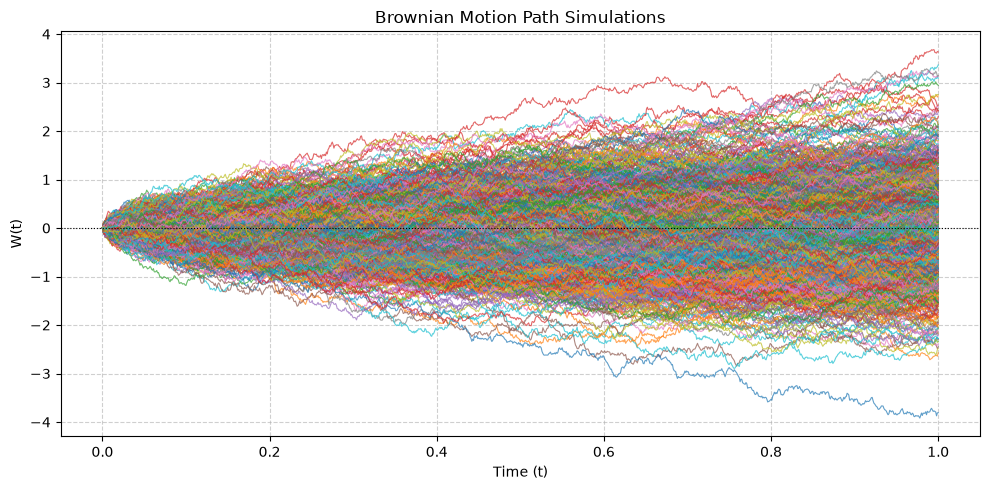

In [6]:
import matplotlib.pyplot as plt
import numpy as np


def simulate_brownian_motion(T=1.0, N=1000, n_paths=5, seed=None):
    """Simulates n_paths trajectories of Brownian motion.

    Parameters:
    -----------
    T : float
        Time horizon (e.g., 1 year)
    N : int
        Number of time steps
    n_paths : int
        Number of paths to simulate
    seed : int, optional
        Seed for random number generator reproducibility

    Returns:
    --------
    t : ndarray of shape (N+1,)
        Array of time steps
    W : ndarray of shape (n_paths, N+1)
        Matrix containing the simulated paths
    """
    
    rng = np.random.default_rng(seed)
    dt = T / N
    t = np.linspace(0, T, N + 1)

    # Gaussian increments dW ~ N(0, dt)
    dW = rng.normal(0.0, np.sqrt(dt), size=(n_paths, N))

    # Brownian motion (W_0 = 0)
    W = np.zeros((n_paths, N + 1))
    W[:, 1:] = np.cumsum(dW, axis=1)

    return t, W


# Run the simulation
t, W = simulate_brownian_motion(n_paths=1000, seed=42)

# Plotting
plt.figure(figsize=(10, 5))
plt.plot(t, W.T, alpha=0.7, linewidth=0.8)
plt.title("Brownian Motion Path Simulations")
plt.xlabel("Time (t)")
plt.ylabel("W(t)")
plt.grid(True, linestyle="--", alpha=0.6)
plt.axhline(0, color="black", linewidth=0.8, linestyle=":")
plt.tight_layout()
plt.show()